# Denglisch Corpus - Data Inspection

Exploratory data analysis of the **original** Denglisch Corpus of German-English Code-Switching
(Osmelak & Wintner, 2023), before project-specific preprocessing/label-mapping is applied.

This notebook inspects the raw corpus release downloaded from
[HaifaCLG/Denglisch](https://github.com/HaifaCLG/Denglisch) and stored in `data/raw/`:

- `Manu_corpus.csv` - manually annotated subset, **detailed** annotation scheme (e.g. `1`, `2`, `3a`, `<punct>`, `<EOS>`, ...)
- `Manu_corpus_collapsed.csv` - the same subset, **collapsed** scheme (`D`, `E`, `O`, `SD`, `SE`, `SO`, `M`)

Goals:
1. Verify the raw file structure (columns, dtypes, missing values).
2. Quantify corpus size (sources, comments/posts, sentences, tokens).
3. Visualize the label distribution under both annotation schemes.
4. Inspect token/sentence length distributions.
5. Surface example code-switched sentences and the most frequent German/English tokens.
6. Sanity-check the DE/EN/NEUT mapping used by `src/corpus_converter.py`.


In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 4)

DATA_RAW = Path("../data/raw")
COLLAPSED_PATH = DATA_RAW / "Manu_corpus_collapsed.csv"
DETAILED_PATH = DATA_RAW / "Manu_corpus.csv"

assert COLLAPSED_PATH.exists(), f"Missing {COLLAPSED_PATH} - see README 'Data Acquisition' to download it."
assert DETAILED_PATH.exists(), f"Missing {DETAILED_PATH} - see README 'Data Acquisition' to download it."
print("Found raw corpus files:", COLLAPSED_PATH.name, "and", DETAILED_PATH.name)


Found raw corpus files: Manu_corpus_collapsed.csv and Manu_corpus.csv


## 1. Raw File Structure

In [2]:
collapsed_df = pd.read_csv(COLLAPSED_PATH, keep_default_na=False, dtype=str)
print("Shape:", collapsed_df.shape)
print("\nColumns:", list(collapsed_df.columns))
print("\nDtypes:")
print(collapsed_df.dtypes)
collapsed_df.head(10)


Shape: (75013, 6)

Columns: ['source', 'user_name', 'sen_id', 'sen_num', 'token', 'categ']

Dtypes:
source       str
user_name    str
sen_id       str
sen_num      str
token        str
categ        str
dtype: object


,source,user_name,sen_id,sen_num,token,categ
0,berlin_2014,user116007,clki7rm,1,Not,E
1,berlin_2014,user116007,clki7rm,1,quite,E
2,berlin_2014,user116007,clki7rm,1,.,O
3,berlin_2014,user116007,clki7rm,2,From,E
4,berlin_2014,user116007,clki7rm,2,the,E
5,berlin_2014,user116007,clki7rm,2,Wiki,SO
6,berlin_2014,user116007,clki7rm,2,page,E
7,berlin_2014,user116007,clki7rm,2,(,O
8,berlin_2014,user116007,clki7rm,2,and,E
9,berlin_2014,user116007,clki7rm,2,this,E


In [3]:
empty_tokens = (collapsed_df["token"].str.strip() == "").sum()
print("Empty-string token rows (EOS/EOP markers):", empty_tokens)
print("\nNull counts per column:")
print(collapsed_df.isna().sum())


Empty-string token rows (EOS/EOP markers): 3

Null counts per column:
source       0
user_name    0
sen_id       0
sen_num      0
token        0
categ        0
dtype: int64


## 2. Corpus Size Summary

In [4]:
num_sources = collapsed_df["source"].nunique()
num_comments = collapsed_df.groupby(["source", "sen_id"]).ngroups
num_sentences = collapsed_df.groupby(["source", "sen_id", "sen_num"]).ngroups
num_tokens = len(collapsed_df)

print(f"Unique subreddit sources:        {num_sources}")
print(f"Unique comments/posts (sen_id):  {num_comments}")
print(f"Unique sentences (sen_id+num):   {num_sentences}")
print(f"Total token rows:                {num_tokens}")


Unique subreddit sources:        34
Unique comments/posts (sen_id):  962
Unique sentences (sen_id+num):   4202
Total token rows:                75013


## 3. Label Distribution - Collapsed Scheme

`D`=German, `E`=English, `O`=Other (punctuation/numbers), `SD`/`SE`=Shared-German/English,
`SO`=Shared-Other, `M`=Mixed morphology.

In [5]:
collapsed_counts = collapsed_df["categ"].value_counts()
print(collapsed_counts)


categ
E     29918
D     29730
O     12505
SO     1108
SD      807
SE      699
M       246
Name: count, dtype: int64


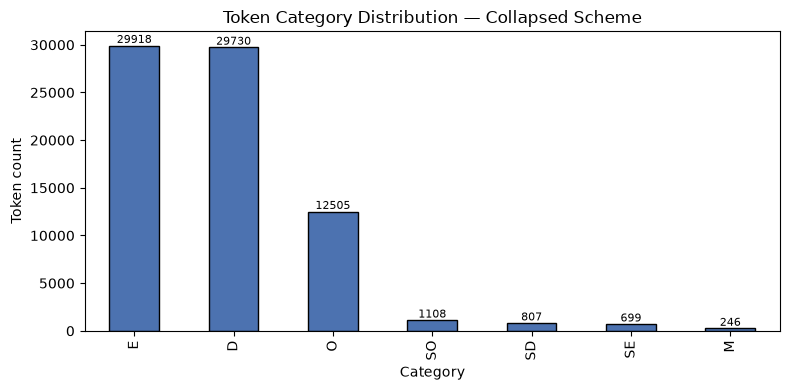

In [6]:
ax = collapsed_counts.plot(kind="bar", color="#4C72B0", edgecolor="black")
ax.set_title("Token Category Distribution \u2014 Collapsed Scheme")
ax.set_xlabel("Category")
ax.set_ylabel("Token count")
for i, v in enumerate(collapsed_counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()


## 4. Label Distribution - Detailed Scheme

The original, finer-grained annotation scheme (e.g. `1`/`2` for German/English, `3a*` for shared
words, `4*` for mixed morphology, plus structural markers `<punct>`, `<EOS>`, `<EOP>`, `<url>`).

In [7]:
detailed_df = pd.read_csv(DETAILED_PATH, keep_default_na=False, dtype=str)
detailed_counts = detailed_df["categ"].value_counts()
print(f"Detailed scheme has {detailed_df['categ'].nunique()} distinct category codes.")
print(detailed_counts)


Detailed scheme has 31 distinct category codes.
categ
1          29880
2          29605
<punct>    11090
<EOS>       4188
<EOP>       3467
4b          1037
3a           573
3a-D         485
3a-E         392
3a-AD        262
4a           243
3a-AE        230
<url>        209
4c           118
3-O          110
3c-C         100
3c-M          98
4d            88
3b            87
4b-D          74
3-E           61
3-D           60
4d-D          51
4             51
3c-EC         28
4d-E          21
4b-E          17
4e-E          16
3c            14
3              7
3c-EM          6
Name: count, dtype: int64


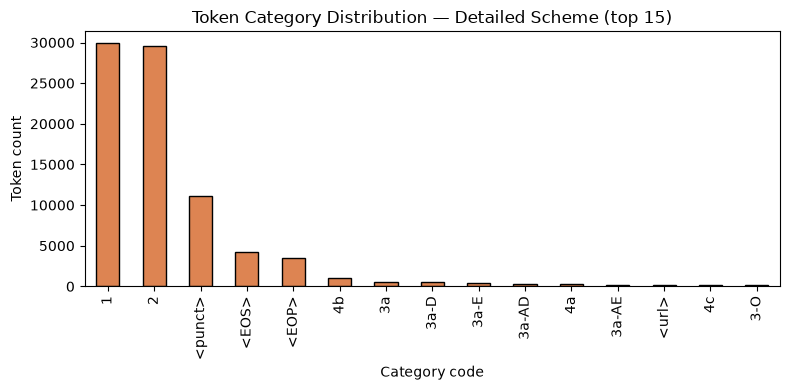

In [8]:
top_n = 15
top_counts = detailed_counts.head(top_n)
ax = top_counts.plot(kind="bar", color="#DD8452", edgecolor="black")
ax.set_title(f"Token Category Distribution \u2014 Detailed Scheme (top {top_n})")
ax.set_xlabel("Category code")
ax.set_ylabel("Token count")
plt.tight_layout()
plt.show()


## 5. Token Length Distribution

count    75010.000000
mean         4.631782
std          5.922234
min          1.000000
25%          2.000000
50%          4.000000
75%          6.000000
max       1233.000000
Name: token, dtype: float64


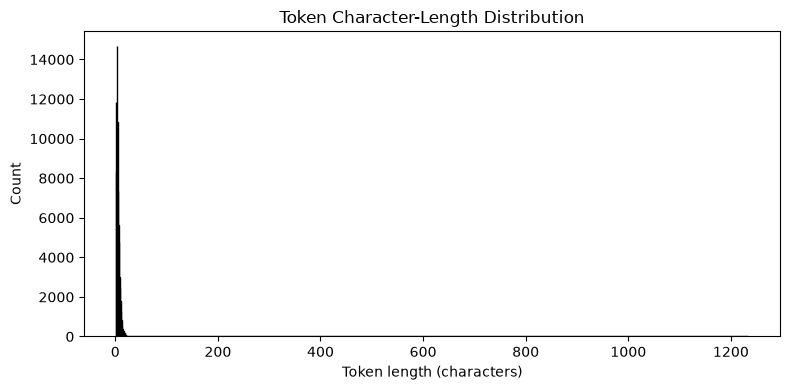

In [9]:
token_lengths = collapsed_df.loc[collapsed_df["token"].str.strip() != "", "token"].str.len()
print(token_lengths.describe())

fig, ax = plt.subplots()
ax.hist(token_lengths, bins=range(1, int(token_lengths.max()) + 2), color="#55A868", edgecolor="black")
ax.set_title("Token Character-Length Distribution")
ax.set_xlabel("Token length (characters)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


## 6. Sentence Length Distribution

count    4202.000000
mean       17.851023
std        19.806255
min         1.000000
25%         8.000000
50%        14.000000
75%        22.000000
max       700.000000
dtype: float64


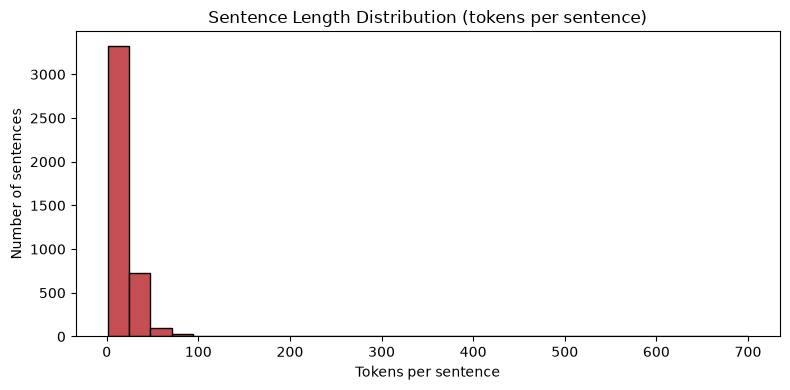

In [10]:
non_empty = collapsed_df[collapsed_df["token"].str.strip() != ""]
sentence_lengths = non_empty.groupby(["source", "sen_id", "sen_num"]).size()
print(sentence_lengths.describe())

fig, ax = plt.subplots()
ax.hist(sentence_lengths, bins=30, color="#C44E52", edgecolor="black")
ax.set_title("Sentence Length Distribution (tokens per sentence)")
ax.set_xlabel("Tokens per sentence")
ax.set_ylabel("Number of sentences")
plt.tight_layout()
plt.show()


## 7. Source Subreddit Distribution

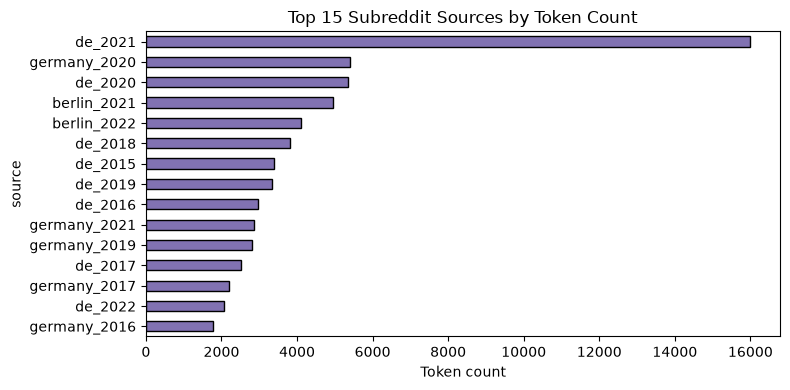

In [11]:
source_counts = collapsed_df["source"].value_counts().head(15)
ax = source_counts.plot(kind="barh", color="#8172B2", edgecolor="black")
ax.invert_yaxis()
ax.set_title("Top 15 Subreddit Sources by Token Count")
ax.set_xlabel("Token count")
plt.tight_layout()
plt.show()


## 8. Example Code-Switched Sentences

In [12]:
def reconstruct_sentences(df):
    sentences = {}
    for key, group in df.groupby(["source", "sen_id", "sen_num"], sort=False):
        pairs = [(tok, cat) for tok, cat in zip(group["token"], group["categ"]) if tok.strip()]
        if pairs:
            sentences[key] = pairs
    return sentences

sentences = reconstruct_sentences(collapsed_df)

code_switched = {
    key: toks for key, toks in sentences.items()
    if ({"D", "SD"} & {c for _, c in toks}) and ({"E", "SE"} & {c for _, c in toks})
}

print(f"{len(code_switched)} of {len(sentences)} sentences contain both German and English tokens "
      f"({100 * len(code_switched) / len(sentences):.1f}%).")

for key, toks in list(code_switched.items())[:5]:
    rendered = " ".join(f"{tok}[{cat}]" for tok, cat in toks)
    print(f"\n(source={key[0]}, comment={key[1]}, sentence {key[2]}):\n  {rendered}")


1509 of 4202 sentences contain both German and English tokens (35.9%).

(source=berlin_2014, comment=clki7rm, sentence 2):
  From[E] the[E] Wiki[SO] page[E] ([O] and[E] this[E] squares[E] with[E] the[E] EStG[D] as[E] best[E] I[E] could[E] tell[E] )[O] :[O] In[D] Deutschland[D] wohnende[D] ausländische[D] Staatsbürger[D] ,[O] die[D] nicht[D] Angehörige[D] eines[D] Mitgliedstaates[D] der[D] Europäischen Union[SD] sind[D] ,[O] haben[D] im[D] Regelfall[D] ebenfalls[D] einen[D] Kindergeldanspruch[D] ,[O] wenn[D] sie[D] eine[D] Niederlassungserlaubnis[D] oder[D] Aufenthaltserlaubnis[D] besitzen[D] .[O]

(source=berlin_2022, comment=ifkl08d, sentence 1):
  You[E] can[E] offer[E] to[E] pay[E] privately[E] ,[O] but[E] the[E] Kita[D] may[E] not[E] be[E] able[E] to[E] give[E] you[E] a[E] place[E] anyway[E] .[O]

(source=berlin_2022, comment=ifkl08d, sentence 4):
  Exceptions[E] are[E] sometimes[E] possible[E] ,[O] depends[E] on[E] the[E] Kita[D] ,[O] but[E] think[E] of[E] it[E] this[E] way[E] :[O

## 9. Most Frequent Tokens by Language

In [13]:
def top_tokens(df, categories, n=15, min_len=2):
    counter = Counter(
        tok.lower() for tok, cat in zip(df["token"], df["categ"])
        if cat in categories and tok.strip() and len(tok) >= min_len
    )
    return counter.most_common(n)

print("Top German tokens (D/SD):")
for tok, count in top_tokens(collapsed_df, {"D", "SD"}):
    print(f"  {tok:<15} {count}")

print("\nTop English tokens (E/SE):")
for tok, count in top_tokens(collapsed_df, {"E", "SE"}):
    print(f"  {tok:<15} {count}")


Top German tokens (D/SD):
  die             816
  und             758
  der             580
  ich             573
  ist             520
  in              504
  das             496
  nicht           452
  zu              358
  es              334
  mit             287
  ein             265
  den             263
  auch            244
  aber            244

Top English tokens (E/SE):
  the             1351
  to              890
  and             693
  you             632
  in              593
  of              571
  is              482
  for             390
  that            363
  it              343
  not             238
  or              234
  are             215
  if              198
  with            195


## 10. Sanity-Checking the Project's Label Mapping

Replays the exact mapping used by `src/corpus_converter.py` directly on the raw CSV, so the
counts below should match that script's log output (compare against a prior
`python src/corpus_converter.py` run).

In [14]:
LABEL_MAP = {
    "D": "DE", "SD": "DE",
    "E": "EN", "SE": "EN",
    "O": "NEUT",
    "SO": None,
    "M": None,
}

has_token = collapsed_df["token"].str.strip() != ""
mapped = collapsed_df["categ"].map(LABEL_MAP)

retained = has_token & mapped.notna()
excluded = has_token & mapped.isna()

print("Retained tokens:", int(retained.sum()))
print("Excluded tokens:", int(excluded.sum()))
print(f"Excluded percentage: {100 * excluded.sum() / has_token.sum():.2f}%")

print("\nExcluded breakdown by original category:")
print(collapsed_df.loc[excluded, "categ"].value_counts())

print("\nResulting DE/EN/NEUT distribution:")
print(mapped[retained].value_counts())


Retained tokens: 73656
Excluded tokens: 1354
Excluded percentage: 1.81%

Excluded breakdown by original category:
categ
SO    1108
M      246
Name: count, dtype: int64

Resulting DE/EN/NEUT distribution:
categ
EN      30617
DE      30537
NEUT    12502
Name: count, dtype: int64


## Summary

- The collapsed scheme's token counts and excluded-category breakdown above should match the
  log output of `python src/corpus_converter.py --input data/raw/Manu_corpus_collapsed.csv
  --output data/raw/denglisch.json`.
- `M` (mixed morphology) and `SO` (shared-other) tokens are excluded from the project's
  DE/EN/NEUT dataset because they have no reliable single-language assignment (see the paper's
  Data Preparation section and `README.md`).
- Code-switched sentences (containing both German and English tokens) make up a substantial
  share of the corpus, consistent with Osmelak & Wintner's (2023) finding that most switches are
  short insertions into otherwise monolingual sentences.